# 03. Preliminary Drift Exploration

## Objectives

- Compare feature distributions across temporal blocks.
- Measure PSI, KS and missing-rate drift.
- Identify features with substantial distribution changes.
- Examine drift patterns during validation and test.

Reference window: Day 1–30.
Current window: Each 7-day evaluation block.
Feature set: NoCardID.

This notebook does not tune retraining policies.

## 1. Import và cấu hình

In [4]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_config, load_ieee_transactions

from src.data_profiling import export_report

from src.temporal_analysis import add_temporal_metadata, assign_experiment_blocks

from src.drift_metrics import feature_drift_report

config = load_config()

drift_config = config["drift_eda"]
ieee_config = config["datasets"]["ieee_cis"]

REPORT_DIR = PROJECT_ROOT / "reports/data_profiling/ieee_cis"

FIGURE_DIR = PROJECT_ROOT / "reports/figures/ieee_cis"

RANDOM_SEED = config["project"]["random_seed"]

## 2. Đọc dữ liệu và xác định features

In [5]:
dictionary = pd.read_csv(REPORT_DIR / "transaction_data_dictionary.csv")

feature_set = drift_config["feature_set"]

feature_flag = {
    "NoCardID": "no_card_id",
    "FullFeatures": "full_features",
}[feature_set]

features = dictionary.loc[dictionary[feature_flag].eq(True), "column_name"].tolist()

categorical_features = dictionary.loc[
    dictionary["feature_group"].isin(
        [
            "Product category",
            "Card information",
            "Address information",
            "Email domain",
            "Matching features",
        ]
    ),
    "column_name",
].tolist()

categorical_features = [col for col in categorical_features if col in features]

metadata_columns = ["TransactionID", "TransactionDT", "isFraud"]

df = load_ieee_transactions(usecols=metadata_columns + features)

time_origin = df["TransactionDT"].min()

temporal_df = add_temporal_metadata(
    df[["TransactionID", "TransactionDT"]], time_origin=time_origin
)

temporal_df = assign_experiment_blocks(temporal_df, config["temporal_split"])

print("Feature set:", feature_set)
print("Number of features:", len(features))
print("Number of blocks:", temporal_df["block_id"].nunique())

assert temporal_df["block_id"].nunique() == 21

Feature set: NoCardID
Number of features: 381
Number of blocks: 21


## 3. Xác định Reference Window

In [6]:
reference_mask = temporal_df["phase"].eq(drift_config["reference_phase"])

reference_df = df.loc[reference_mask, features]

block_ids = sorted(temporal_df["block_id"].dropna().unique().tolist())

print("Reference samples:", len(reference_df))
print("Reference days:", "1–30")
print("Evaluation blocks:", block_ids)

Reference samples: 134339
Reference days: 1–30
Evaluation blocks: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]


## 4. Tính Drift Metrics cho từng block

In [7]:
all_reports = []

for block_id in tqdm(block_ids, desc="Analyzing drift"):

    mask = temporal_df["block_id"].eq(block_id).fillna(False)

    current_df = df.loc[mask, features]

    report = feature_drift_report(
        reference_df=reference_df,
        current_df=current_df,
        features=features,
        categorical_features=categorical_features,
        config=drift_config,
        random_seed=RANDOM_SEED,
    )

    report["block_id"] = int(block_id)

    report["phase"] = temporal_df.loc[mask, "phase"].iloc[0]

    all_reports.append(report)

    del current_df

drift_results = pd.concat(all_reports, ignore_index=True)

display(drift_results.head())

export_report(drift_results, REPORT_DIR / "feature_drift_by_block.csv")

Analyzing drift:   0%|          | 0/21 [00:00<?, ?it/s]

,feature,feature_type,psi,ks_statistic,reference_non_missing,current_non_missing,reference_missing_rate,current_missing_rate,missing_rate_change,missing_rate_drift,sufficient_samples,block_id,phase
0,TransactionAmt,numerical,0.090254,0.048100,134339,23467,0.000000,0.000000,0.000000,0.000000,True,1,validation
1,ProductCD,categorical,0.389897,NaN,134339,23467,0.000000,0.000000,0.000000,0.000000,True,1,validation
2,dist1,numerical,0.110739,0.021400,40146,10765,0.701159,0.541271,-0.159888,0.159888,True,1,validation
3,dist2,numerical,0.012934,0.087075,11737,1495,0.912631,0.936294,0.023662,0.023662,True,1,validation
4,C1,numerical,0.034879,0.093000,134339,23467,0.000000,0.000000,0.000000,0.000000,True,1,validation


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\feature_drift_by_block.csv


## 5. Tổng hợp Drift theo block

In [8]:
moderate_threshold = drift_config["psi_moderate_threshold"]

high_threshold = drift_config["psi_high_threshold"]

drift_summary = (
    drift_results.groupby(["block_id", "phase"])
    .agg(
        valid_psi_features=("psi", "count"),
        median_psi=("psi", "median"),
        p90_psi=("psi", lambda x: x.quantile(0.90)),
        moderate_psi_features=(
            "psi",
            lambda x: ((x >= moderate_threshold) & (x < high_threshold)).sum(),
        ),
        high_psi_features=("psi", lambda x: (x >= high_threshold).sum()),
        valid_ks_features=("ks_statistic", "count"),
        median_ks=("ks_statistic", "median"),
        mean_missing_drift=("missing_rate_drift", "mean"),
    )
    .reset_index()
)

drift_summary["high_psi_ratio"] = (
    drift_summary["high_psi_features"] / drift_summary["valid_psi_features"]
)

drift_summary = drift_summary.sort_values("block_id")

display(drift_summary)

export_report(drift_summary, REPORT_DIR / "block_drift_summary.csv")

,block_id,phase,valid_psi_features,median_psi,p90_psi,moderate_psi_features,high_psi_features,valid_ks_features,median_ks,mean_missing_drift,high_psi_ratio
0,1,validation,381,0.209985,0.378355,152,117,371,0.028590,0.152685,0.307087
1,2,validation,381,0.329409,0.461010,32,238,371,0.037100,0.169305,0.624672
2,3,validation,381,0.348535,0.467622,26,238,371,0.042977,0.169593,0.624672
3,4,validation,381,0.299610,0.449503,24,240,371,0.038249,0.164320,0.629921
4,5,validation,381,0.302488,0.501098,11,252,371,0.032988,0.171446,0.661417
5,6,validation,381,0.287305,0.462459,26,252,371,0.035864,0.169931,0.661417
6,7,validation,381,0.199295,0.316169,156,118,371,0.038900,0.146538,0.309711
7,8,validation,381,0.277901,0.480619,23,255,371,0.037800,0.171783,0.669291
8,9,test,381,0.416788,0.566257,2,272,371,0.040200,0.193636,0.713911
9,10,test,381,0.363384,0.544324,24,252,371,0.037658,0.184241,0.661417


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\block_drift_summary.csv


## 6. Vẽ Drift theo thời gian (*)

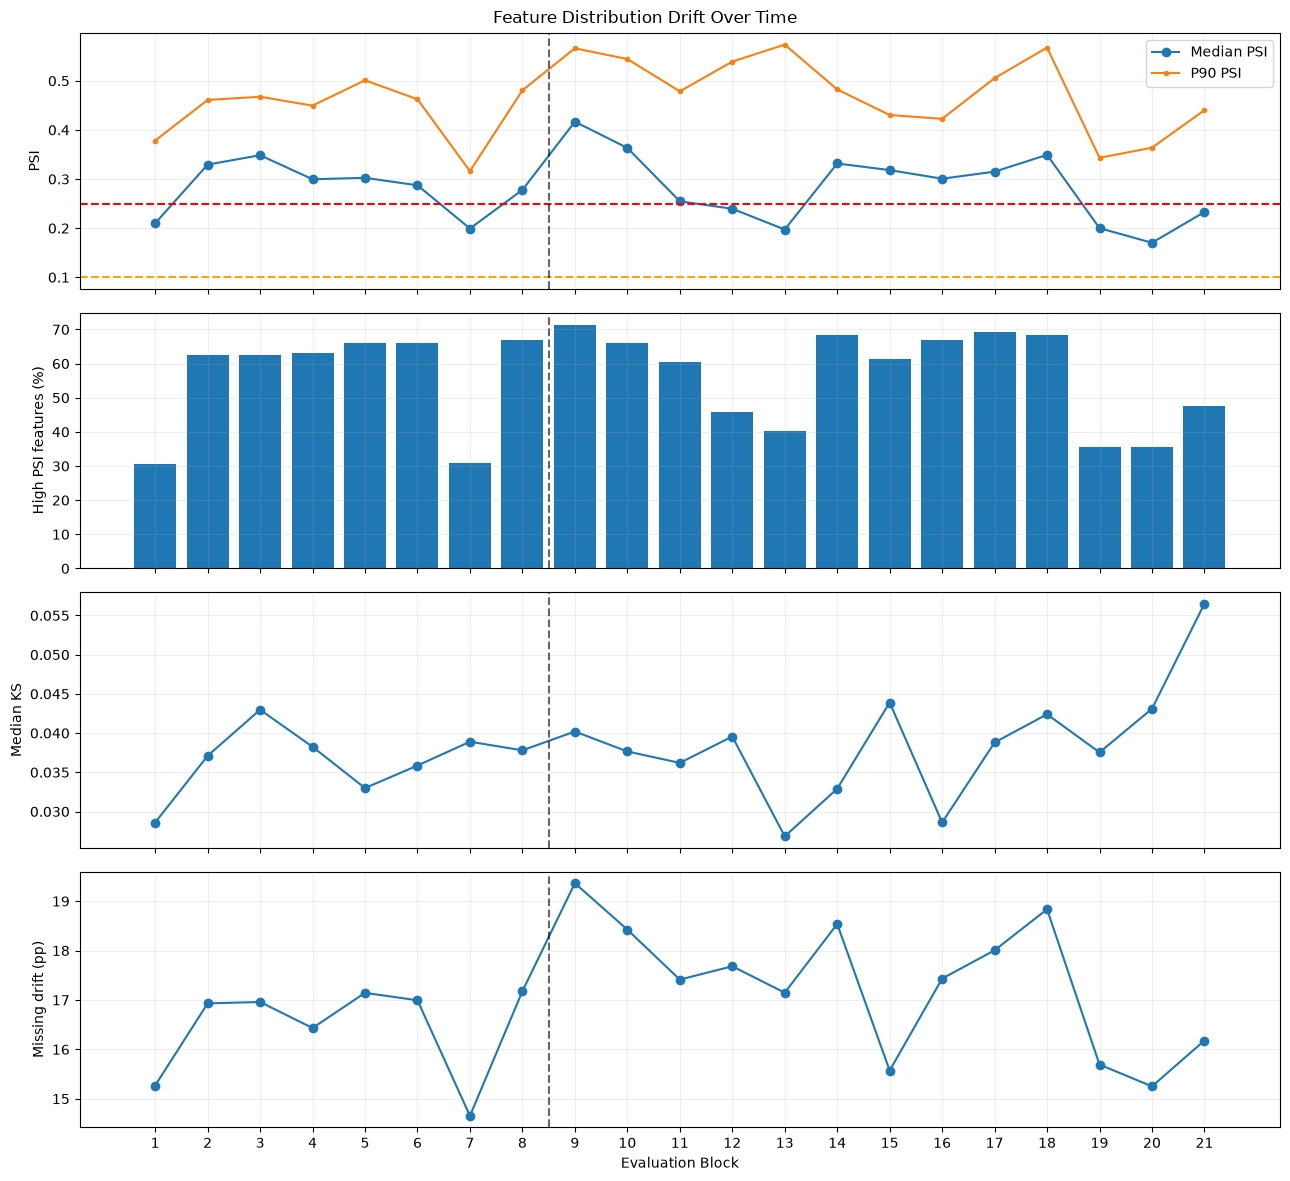

In [9]:
fig, axes = plt.subplots(4, 1, figsize=(13, 12), sharex=True)

x = drift_summary["block_id"]

axes[0].plot(x, drift_summary["median_psi"], marker="o", label="Median PSI")

axes[0].plot(x, drift_summary["p90_psi"], marker=".", label="P90 PSI")

axes[0].axhline(0.1, linestyle="--", color="orange")

axes[0].axhline(0.25, linestyle="--", color="red")

axes[0].set_ylabel("PSI")
axes[0].legend()

axes[1].bar(x, drift_summary["high_psi_ratio"] * 100)

axes[1].set_ylabel("High PSI features (%)")

axes[2].plot(x, drift_summary["median_ks"], marker="o")

axes[2].set_ylabel("Median KS")

axes[3].plot(x, drift_summary["mean_missing_drift"] * 100, marker="o")

axes[3].set_ylabel("Missing drift (pp)")
axes[3].set_xlabel("Evaluation Block")

for ax in axes:

    ax.axvline(8.5, linestyle="--", color="black", alpha=0.6)

    ax.grid(alpha=0.2)

axes[-1].set_xticks(range(1, 22))

fig.suptitle("Feature Distribution Drift Over Time")

plt.tight_layout()

plt.savefig(FIGURE_DIR / "temporal_drift_summary.png", dpi=300, bbox_inches="tight")

plt.show()

## 7. Top features có Drift lớn

,feature,mean_psi,max_psi,mean_ks,mean_missing_drift,valid_blocks
98,V151,0.750235,0.803521,0.196432,0.244739,8
113,V165,0.739221,1.015804,0.196242,0.244739,8
89,V143,0.725186,0.790779,0.194167,0.244739,8
90,V144,0.700660,0.750022,0.188129,0.244739,8
91,V145,0.692725,0.745178,0.197700,0.244739,8
97,V150,0.690231,0.744716,0.197700,0.244739,8
99,V152,0.676546,0.813067,0.174626,0.244739,8
106,V159,0.674924,0.746720,0.194153,0.244739,8
108,V160,0.661867,0.746456,0.179785,0.244739,8
114,V166,0.650318,0.756182,0.182618,0.244739,8


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\validation_feature_drift_ranking.csv


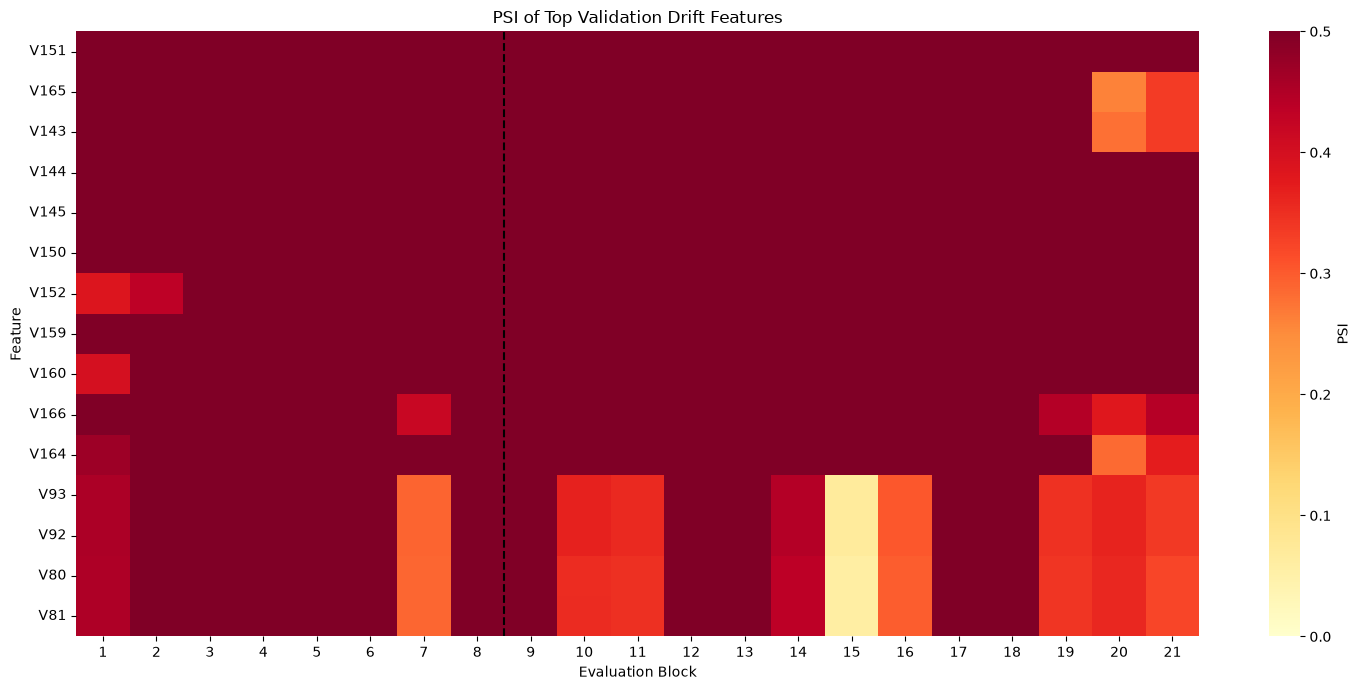

In [10]:
validation_drift = drift_results.loc[drift_results["phase"].eq("validation")]

feature_ranking = (
    validation_drift.groupby("feature")
    .agg(
        mean_psi=("psi", "mean"),
        max_psi=("psi", "max"),
        mean_ks=("ks_statistic", "mean"),
        mean_missing_drift=("missing_rate_drift", "mean"),
        valid_blocks=("psi", "count"),
    )
    .reset_index()
)

feature_ranking = feature_ranking.loc[feature_ranking["valid_blocks"] >= 4].sort_values(
    "mean_psi", ascending=False
)

top_features = feature_ranking.head(drift_config["top_k_features"])["feature"].tolist()

display(feature_ranking.head(15))

export_report(feature_ranking, REPORT_DIR / "validation_feature_drift_ranking.csv")

heatmap_data = (
    drift_results.loc[drift_results["feature"].isin(top_features)]
    .pivot(index="feature", columns="block_id", values="psi")
    .reindex(top_features)
)

plt.figure(figsize=(15, 7))

ax = sns.heatmap(
    heatmap_data, cmap="YlOrRd", vmin=0, vmax=0.5, cbar_kws={"label": "PSI"}
)

ax.axvline(8, color="black", linestyle="--")

plt.title("PSI of Top Validation Drift Features")
plt.xlabel("Evaluation Block")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(FIGURE_DIR / "top_feature_drift_heatmap.png", dpi=300, bbox_inches="tight")

plt.show()

## Conclusion

Preliminary drift analysis evaluates changes in feature
distributions using PSI, KS and missing-rate drift.

The reference distribution is defined using the warmup
period. Feature ranking is based on validation blocks.

Test-period results are descriptive and must not be used
to tune drift thresholds or retraining policies.

Feature distribution drift does not independently
establish concept drift or model performance degradation.